# Full-throttle speed loss: 2025 vs 2026 qualifying, paired by straight

The same pipeline (`flatout.run_session`, same cleaning and QC) runs on 2025 qualifying at every circuit that has also hosted 2026 qualifying so far. Circuits are matched by OpenF1 `circuit_key`, not by event name; Madrid (new in 2026) and the 2026 Sepang round have no 2025 counterpart. A straight is compared when it appears in both years (same circuit, corner label and main-straight flag) with >= 10 clean drivers in each year.

**Caveats.** 2025 cars differ in many ways (MGU-H, 120 kW MGU-K, DRS in qualifying, aerodynamics), so year differences reflect the whole 2026 package, not one rule. Pooling 2026 across PUs is justified by the season result (no detectable PU difference), which is not proof that none exists. C5.2.8 values are not computed for 2025 (a 2026 rule). Descriptive only.

In [1]:
import json
import re
from pathlib import Path

import fastf1
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from flatout import OPENF1_CACHE, FIG, PU_2025, XY_UNIT_M, caption, load_quali, openf1_session_key, run_session, to_seconds

MIN_CLEAN_DRIVERS = 10
OUT25, OUT26 = Path("data/season2025"), Path("data/season")
OUT25.mkdir(parents=True, exist_ok=True)


def circuit_of(year, rnd):
    """(OpenF1 session_key, circuit_key, circuit_short_name) of an event's main Qualifying."""
    key = openf1_session_key(year, rnd)
    ses = pd.DataFrame(json.loads((OPENF1_CACHE / f"sessions_{year}_qualifying.json").read_text()))
    row = ses[ses.session_key == key]
    return (key, int(row.circuit_key.iloc[0]), row.circuit_short_name.iloc[0]) if len(row) else (key, None, None)


qc26 = pd.read_csv(OUT26 / "qc_summary.csv")
qc26 = qc26[qc26.Status.eq("ok") & ~qc26.Event.eq("Bahrain Grand Prix")]  # 2026 Bahrain GP was held at Sepang: no 2025 counterpart
e26 = pd.DataFrame([dict(Round26=r.Round, Event26=r.Event, **dict(zip(["Key26", "Circuit", "CircuitName"], circuit_of(2026, r.Round))))
                    for r in qc26.itertuples()])
sch25 = fastf1.get_event_schedule(2025, include_testing=False)
sch25 = sch25[sch25.EventFormat.isin(["conventional", "sprint_qualifying"])]
e25 = pd.DataFrame([dict(Round25=r.RoundNumber, Event25=r.EventName, Location25=r.Location,
                         **dict(zip(["Key25", "Circuit", "_"], circuit_of(2025, r.RoundNumber)))) for r in sch25.itertuples()]).drop(columns="_")
pairs = e26.merge(e25, on="Circuit").sort_values("Round26").reset_index(drop=True)
print("2025 team -> PU:", PU_2025, "\n")
print(pairs[["CircuitName", "Round25", "Event25", "Round26", "Event26", "Key25", "Key26"]].to_string(index=False))
print("\n2026 sessions without a 2025 counterpart:", sorted(set(e26.Event26) - set(pairs.Event26)) or "none")

req         WARNING 	DEFAULT CACHE ENABLED! (56.0 KB) C:\Users\User\AppData\Local\Temp\fastf1


2025 team -> PU: {'Mercedes': 'Mercedes', 'McLaren': 'Mercedes', 'Williams': 'Mercedes', 'Aston Martin': 'Mercedes', 'Ferrari': 'Ferrari', 'Haas F1 Team': 'Ferrari', 'Kick Sauber': 'Ferrari', 'Red Bull Racing': 'Honda RBPT', 'Racing Bulls': 'Honda RBPT', 'Alpine': 'Renault'} 

      CircuitName  Round25               Event25  Round26               Event26  Key25  Key26
        Melbourne        1 Australian Grand Prix        1 Australian Grand Prix   9689  11230
         Shanghai        2    Chinese Grand Prix        2    Chinese Grand Prix   9994  11241
           Suzuka        3   Japanese Grand Prix        3   Japanese Grand Prix  10002  11249
            Miami        6      Miami Grand Prix        4      Miami Grand Prix  10029  11276
         Montreal       10   Canadian Grand Prix        5   Canadian Grand Prix   9959  11287
      Monte Carlo        8     Monaco Grand Prix        6     Monaco Grand Prix   9975  11295
        Catalunya        9    Spanish Grand Prix        7  Barce

## 2025 sessions (same cleaning and QC)

In [2]:
rows = []
for p in pairs.itertuples():
    row = dict(Round25=p.Round25, Event25=p.Event25, Circuit=p.CircuitName)
    try:
        tables, qc = run_session(2025, p.Round25, openf1_session=p.Key25)
        stem = OUT25 / f"{p.Round25:02d}_{re.sub(r'[^A-Za-z0-9]+', '_', p.Location25).strip('_').lower()}"
        to_seconds(tables["sectors"]).to_csv(f"{stem}_sectors.csv", index=False)
        to_seconds(tables["segments"]).to_csv(f"{stem}_segments.csv", index=False)
        tables["exclusions"].to_csv(f"{stem}_exclusions.csv", index=False)
        row.update(Status="ok", **{k: qc[k] for k in ["brake_source", "circuit_info", "push_laps", "push_lap_frozen_pct_mean"]})
    except Exception as e:
        row.update(Status=f"error: {type(e).__name__}: {e}")
    rows.append(row)
    print(f"2025 round {p.Round25:2d} {p.Event25:<28} {row['Status'][:70]}", flush=True)
qc25 = pd.DataFrame(rows)
qc25.to_csv(OUT25 / "qc_summary.csv", index=False)
qc25.rename(columns={"push_lap_frozen_pct_mean": "FreezeShare_pct"}).round(2)

core        WARNING 	Fixed incorrect tyre stint information for driver '4'


2025 round  1 Australian Grand Prix        ok


2025 round  2 Chinese Grand Prix           ok


2025 round  3 Japanese Grand Prix          ok


2025 round  6 Miami Grand Prix             ok


...

2025 round 15 Dutch Grand Prix             ok


2025 round 16 Italian Grand Prix           ok


2025 round 17 Azerbaijan Grand Prix        ok


2025 round 18 Singapore Grand Prix         ok


,Round25,Event25,Circuit,Status,brake_source,circuit_info,push_laps,FreezeShare_pct
0,1,Australian Grand Prix,Melbourne,ok,OpenF1,ok,87,0.01
1,2,Chinese Grand Prix,Shanghai,ok,OpenF1,ok,96,0.00
2,3,Japanese Grand Prix,Suzuka,ok,OpenF1,ok,94,0.02
3,6,Miami Grand Prix,Miami,ok,OpenF1,ok,93,0.00
4,10,Canadian Grand Prix,Montreal,ok,OpenF1,ok,112,0.03
5,8,Monaco Grand Prix,Monte Carlo,ok,OpenF1,ok,134,0.00
6,9,Spanish Grand Prix,Catalunya,ok,OpenF1,ok,78,0.00
7,11,Austrian Grand Prix,Spielberg,ok,OpenF1,ok,97,0.00
8,12,British Grand Prix,Silverstone,ok,OpenF1,ok,91,0.06
9,13,Belgian Grand Prix,Spa-Francorchamps,ok,OpenF1,ok,83,0.05


In [3]:
_ok = qc25[qc25.Status.eq("ok")]
caption("Table", "qc25", f"2025 qualifying sessions at circuits also raced in 2026: {len(_ok)} of {len(qc25)} ran; freeze share per session "
        f"{_ok.push_lap_frozen_pct_mean.min():.2f}–{_ok.push_lap_frozen_pct_mean.max():.2f} % (mean {_ok.push_lap_frozen_pct_mean.mean():.2f} %); "
        f"brake source: {', '.join(sorted(_ok.brake_source.unique()))}.")

*Table 1. 2025 qualifying sessions at circuits also raced in 2026: 15 of 15 ran; freeze share per session 0.00–0.06 % (mean 0.01 %); brake source: OpenF1.*

## Paired comparison by straight

Per straight and year, across drivers' selected segments: median vmax_position, median clip_delta, the share of drivers whose peak comes before the segment end (vmax_position < 1) and, as a sensitivity check on that share, the share with clip_delta >= 2 km/h. Difference = 2026 − 2025.

In [4]:
def load_year(year, out, rnd_col):
    """Selected segments of one year at the paired circuits, with a straight key (circuit, label, main flag)."""
    frames = []
    for p in pairs.itertuples():
        f = next(out.glob(f"{getattr(p, rnd_col):02d}_*_segments.csv"), None)
        if f is not None:
            frames.append(pd.read_csv(f).assign(Circuit=p.CircuitName))
    d = pd.concat(frames, ignore_index=True)
    d["Straight"] = d.Circuit + " " + np.where(d.CrossesTimingLine, "main", d.Label)
    d = d[d.groupby("Straight").Driver.transform("nunique") >= MIN_CLEAN_DRIVERS]
    return d.assign(Year=year)


seg = pd.concat([load_year(2025, OUT25, "Round25"), load_year(2026, OUT26, "Round26")], ignore_index=True)
per = seg.groupby(["Straight", "Year"]).agg(vmax_position=("vmax_position", "median"), clip_delta=("clip_delta", "median"),
                                            PeakBeforeEnd=("vmax_position", lambda x: (x < 1).mean()),
                                            Clip2Share=("clip_delta", lambda x: (x >= 2).mean()),
                                            Drivers=("Driver", "nunique")).unstack("Year").dropna()
METRICS = {"vmax_position": "median vmax_position", "clip_delta": "median clip_delta (km/h)",
           "PeakBeforeEnd": "share with peak before segment end", "Clip2Share": "share with clip_delta >= 2 km/h"}


def paired_summary(per):
    """Per metric: n straights, median per year, median and IQR of the 2026 - 2025 difference, shares of straights higher/lower in 2026."""
    d = pd.DataFrame({m: per[(m, 2026)] - per[(m, 2025)] for m in METRICS})
    return pd.DataFrame({m: {"n straights": len(d), "median 2025": per[(m, 2025)].median(), "median 2026": per[(m, 2026)].median(),
                             "median difference": d[m].median(), "q25": d[m].quantile(.25), "q75": d[m].quantile(.75),
                             "share 2026 > 2025": (d[m] > 0).mean(), "share 2026 < 2025": (d[m] < 0).mean()} for m in METRICS}).T, d


summary, diff = paired_summary(per)
print(per.round(2).to_string(), "\n")
summary.round(2)

                      vmax_position       clip_delta       PeakBeforeEnd       Clip2Share       Drivers      
Year                           2025  2026       2025  2026          2025  2026       2025  2026    2025  2026
Straight                                                                                                     
Baku T15                       1.00  0.71        0.0  21.5          0.05  1.00       0.00  1.00    20.0  22.0
Baku T3                        1.00  0.94        0.0   2.0          0.30  0.81       0.15  0.57    20.0  21.0
Baku main                      1.00  0.99        0.0   1.0          0.05  0.59       0.00  0.27    20.0  22.0
Catalunya main                 0.94  0.76        2.0  21.0          0.95  1.00       0.60  1.00    20.0  22.0
Hungaroring main               1.00  0.92        0.0   7.0          0.20  0.68       0.05  0.64    20.0  22.0
Melbourne T11                  1.00  0.85        0.0  10.5          0.00  0.94       0.00  0.94    19.0  18.0
Melbourne 

,n straights,median 2025,median 2026,median difference,q25,q75,share 2026 > 2025,share 2026 < 2025
vmax_position,39.0,0.99,0.77,-0.15,-0.29,-0.04,0.00,0.85
clip_delta,39.0,0.50,9.50,7.50,3.50,20.75,0.85,0.00
PeakBeforeEnd,39.0,0.50,1.00,0.31,0.10,0.51,0.87,0.03
Clip2Share,39.0,0.25,1.00,0.40,0.16,0.68,0.87,0.00


In [5]:
caption("Table", "paired", f"{len(diff)} straights present in both years with >= {MIN_CLEAN_DRIVERS} clean drivers each, at "
        f"{per.index.str.rsplit(' ', n=1).str[0].nunique()} circuits. Difference 2026 − 2025 per straight (median, IQR, share of straights with "
        "2026 > 2025): " + "; ".join(
            f"{METRICS[m]}: {diff[m].median():+.2f} (IQR {diff[m].quantile(.25):+.2f} to {diff[m].quantile(.75):+.2f}), 2026 > 2025 on "
            f"{(diff[m] > 0).mean():.0%}" for m in METRICS)
        + ". Speed is reported in integer km/h, so a drag-limited plateau can register a peak before the segment end with negligible speed loss; "
        "the share with clip_delta >= 2 km/h is the sensitivity check on that measure. Year differences reflect the whole 2026 package (no MGU-H, "
        "350 kW MGU-K, no DRS, new aero), not one rule; 2026 is pooled across PUs, justified by the season result (no detectable PU difference), "
        "which is not proof of none. Descriptive.")

*Table 2. 39 straights present in both years with >= 10 clean drivers each, at 15 circuits. Difference 2026 − 2025 per straight (median, IQR, share of straights with 2026 > 2025): median vmax_position: -0.15 (IQR -0.29 to -0.04), 2026 > 2025 on 0%; median clip_delta (km/h): +7.50 (IQR +3.50 to +20.75), 2026 > 2025 on 85%; share with peak before segment end: +0.31 (IQR +0.10 to +0.51), 2026 > 2025 on 87%; share with clip_delta >= 2 km/h: +0.40 (IQR +0.16 to +0.68), 2026 > 2025 on 87%. Speed is reported in integer km/h, so a drag-limited plateau can register a peak before the segment end with negligible speed loss; the share with clip_delta >= 2 km/h is the sensitivity check on that measure. Year differences reflect the whole 2026 package (no MGU-H, 350 kW MGU-K, no DRS, new aero), not one rule; 2026 is pooled across PUs, justified by the season result (no detectable PU difference), which is not proof of none. Descriptive.*

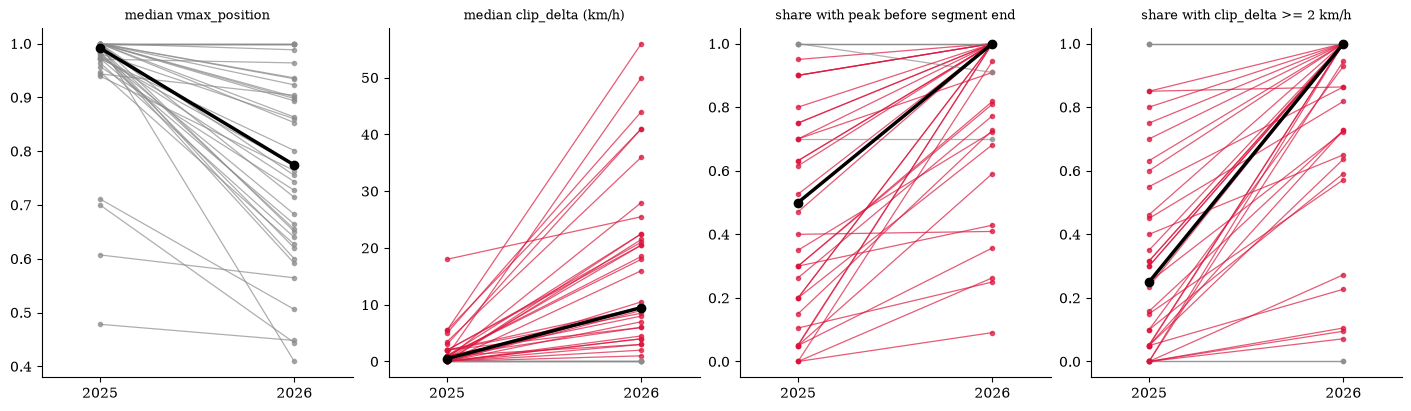

In [6]:
fig, axes = plt.subplots(1, len(METRICS), figsize=(14, 4), layout="constrained")
for ax, (m, label) in zip(axes, METRICS.items()):
    for s, r in per.iterrows():
        up = r[(m, 2026)] > r[(m, 2025)]
        ax.plot([0, 1], [r[(m, 2025)], r[(m, 2026)]], color="crimson" if up else "0.55", lw=0.9, alpha=0.7, marker="o", ms=3)
    ax.plot([0, 1], [per[(m, 2025)].median(), per[(m, 2026)].median()], color="black", lw=2.5, marker="o", ms=6)
    ax.set_xticks([0, 1], ["2025", "2026"])
    ax.set_xlim(-0.3, 1.3)
    ax.set_title(label, fontsize=9)
fig.savefig(FIG / "fig_regs_paired_straights.pdf")
plt.show()

In [7]:
caption("Figure", "paired", f"Paired straights, 2025 vs 2026 ({len(per)} straights): each line is one straight (red = higher in 2026, grey = lower or equal), "
        "black = median across straights. Panels: median vmax_position, median clip_delta, share of drivers whose peak comes before the segment end "
        "(can be inflated by integer-km/h plateaus), share with clip_delta >= 2 km/h. "
        "Year differences reflect the whole 2026 package, not one rule. Descriptive.")

*Figure 1. Paired straights, 2025 vs 2026 (39 straights): each line is one straight (red = higher in 2026, grey = lower or equal), black = median across straights. Panels: median vmax_position, median clip_delta, share of drivers whose peak comes before the segment end (can be inflated by integer-km/h plateaus), share with clip_delta >= 2 km/h. Year differences reflect the whole 2026 package, not one rule. Descriptive.*

## Suzuka: the straight through 130R, 2025 vs 2026

One clean lap per year: the fastest lap among each year's selected T14→T16 segments (freeze-free by selection). Speed is plotted against distance normalised along that segment (0 = segment start, 1 = segment end).

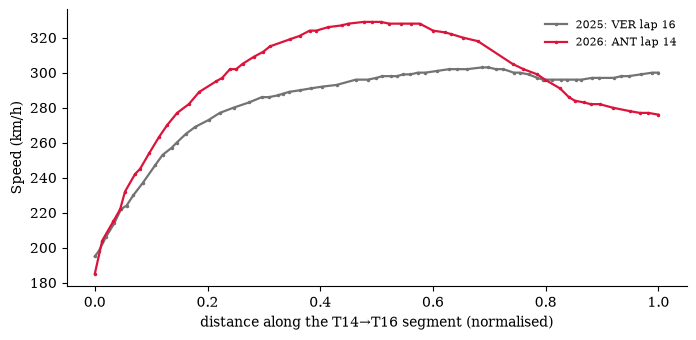

In [8]:
traces = {}
fig, ax = plt.subplots(figsize=(8, 3.6))
for year, out, rnd_col, color in [(2025, OUT25, "Round25", "0.45"), (2026, OUT26, "Round26", "crimson")]:
    rnd = int(pairs.loc[pairs.CircuitName == "Suzuka", rnd_col].iloc[0])
    s16 = pd.read_csv(next(out.glob(f"{rnd:02d}_*_segments.csv")))
    r = s16[(s16.Label == "T16") & ~s16.CrossesTimingLine].sort_values("LapTime_s").iloc[0]
    lap = load_quali(year, rnd).laps.pick_drivers(r.Driver).pick_laps(int(r.LapNumber)).iloc[0]
    car = lap.get_car_data().add_distance()
    car = car[car.Distance.between(r.start_m, r.end_m)]
    x = (car.Distance - r.start_m) / (r.end_m - r.start_m)
    ax.plot(x, car.Speed, color=color, lw=1.6, marker=".", ms=3, label=f"{year}: {r.Driver} lap {int(r.LapNumber)}")
    traces[year] = r
ax.set(xlabel="distance along the T14→T16 segment (normalised)", ylabel="Speed (km/h)")
ax.legend(frameon=False, fontsize=8)
fig.savefig(FIG / "fig_regs_suzuka_t16_traces.pdf")
plt.show()

In [9]:
caption("Figure", "suzuka", "Speed along the Suzuka T14→T16 straight (through 130R), fastest selected lap per year: " + "; ".join(
    f"{y} {r.Driver} lap {int(r.LapNumber)}: peak {r.peak_speed:.0f} km/h at vmax_position {r.vmax_position:.2f}, clip_delta {r.clip_delta:.0f} km/h"
    for y, r in traces.items()) + ". One lap per year; 2025 and 2026 cars differ in many ways (MGU-H, 120 kW MGU-K, DRS, aero). Descriptive.")

*Figure 2. Speed along the Suzuka T14→T16 straight (through 130R), fastest selected lap per year: 2025 VER lap 16: peak 303 km/h at vmax_position 0.70, clip_delta 3 km/h; 2026 ANT lap 14: peak 329 km/h at vmax_position 0.51, clip_delta 53 km/h. One lap per year; 2025 and 2026 cars differ in many ways (MGU-H, 120 kW MGU-K, DRS, aero). Descriptive.*

## Robustness checks

1. **Corner positions.** For each paired circuit, corners present in both years' FastF1 circuit info are compared by X/Y. A circuit is flagged if any corner used to label a matched straight moved more than 50 m between years (layout change, renumbering or a different map frame).
2. **Rain.** A session is flagged as wet if FastF1 weather data report rainfall at any point in qualifying; a circuit is flagged if either year was wet.

The paired result is recomputed excluding each set of flagged circuits.

In [10]:
SHIFT_FLAG_M = 50  # a matched corner that moved more than this between years flags the circuit
circuit_of_straight = per.index.str.rsplit(" ", n=1).str[0]
geo, wet = [], []
for p in pairs.itertuples():
    ses25, ses26 = load_quali(2025, p.Round25), load_quali(2026, p.Round26)
    c25, c26 = ([s.get_circuit_info().corners.drop_duplicates("Number").set_index("Number") for s in (ses25, ses26)])
    common = c25.index.intersection(c26.index)
    shift = np.hypot(c25.loc[common, "X"] - c26.loc[common, "X"], c25.loc[common, "Y"] - c26.loc[common, "Y"]) * XY_UNIT_M
    labels = per.index[circuit_of_straight == p.CircuitName].str.rsplit(" ", n=1).str[1]
    used = sorted({1 if lab == "main" else int(lab[1:]) for lab in labels} & set(common))
    geo.append(dict(Circuit=p.CircuitName, Corners2025=len(c25), Corners2026=len(c26), CommonCorners=len(common),
                    MaxShiftAll_m=shift.max(), MaxShiftMatched_m=shift[used].max() if used else np.nan,
                    MatchedCorners=",".join(f"T{n}" for n in used)))
    for year, ses in [(2025, ses25), (2026, ses26)]:
        w = ses.weather_data
        wet.append(dict(Circuit=p.CircuitName, Year=year, RainfallSamples=int(w["Rainfall"].sum()), WeatherSamples=len(w)))
geo = pd.DataFrame(geo).assign(Flag=lambda x: x.MaxShiftMatched_m > SHIFT_FLAG_M)
wet = pd.DataFrame(wet).assign(Wet=lambda x: x.RainfallSamples > 0)
print(geo.round(1).to_string(index=False), "\n")
print(wet.pivot(index="Circuit", columns="Year", values="Wet").to_string())

core        WARNING 	Fixed incorrect tyre stint information for driver '4'


core        WARNING 	No lap data for driver 18


core        WARNING 	No lap data for driver 55


core        WARNING 	Failed to perform lap accuracy check - all laps marked as inaccurate (driver 18)


core        WARNING 	Failed to perform lap accuracy check - all laps marked as inaccurate (driver 55)


...

core        WARNING 	Fixed incorrect tyre stint information for driver '10'


core        WARNING 	Fixed incorrect tyre stint information for driver '14'


core        WARNING 	Fixed incorrect tyre stint information for driver '23'


core        WARNING 	Fixed incorrect tyre stint information for driver '6'


          Circuit  Corners2025  Corners2026  CommonCorners  MaxShiftAll_m  MaxShiftMatched_m   MatchedCorners  Flag
        Melbourne           14           14             14            0.0                0.0           T9,T11 False
         Shanghai           16           16             16            0.0                0.0           T1,T14 False
           Suzuka           18           18             18            0.0                0.0       T1,T13,T16 False
            Miami           19           19             19            0.0                0.0       T1,T11,T17 False
         Montreal           14           14             14            0.0                0.0        T1,T8,T13 False
      Monte Carlo           19           19             19            0.0                0.0              T10 False
        Catalunya           14           14             14            0.0                0.0               T1 False
        Spielberg           10           10             10            0.

In [11]:
_moved = geo[geo.Flag]
_wetc = sorted(set(wet.loc[wet.Wet, "Circuit"]))
caption("Table", "checks", f"Robustness flags for the {len(pairs)} paired circuits. Corner positions: largest shift of a matched corner between years "
        f"{geo.MaxShiftMatched_m.min():.0f}–{geo.MaxShiftMatched_m.max():.0f} m; flagged (> {SHIFT_FLAG_M} m): "
        f"{', '.join(f'{r.Circuit} ({r.MaxShiftMatched_m:.0f} m)' for r in _moved.itertuples()) or 'none'}"
        + (". All corners have identical coordinates in both years' FastF1 circuit info, so this check cannot detect a layout or numbering "
           "change unless the map itself was updated" if (geo.MaxShiftAll_m == 0).all() else "") + ". Rain during qualifying: "
        + (", ".join(f"{r.Circuit} {r.Year}" for r in wet[wet.Wet].itertuples()) or "none") + ".")

*Table 3. Robustness flags for the 15 paired circuits. Corner positions: largest shift of a matched corner between years 0–0 m; flagged (> 50 m): none. All corners have identical coordinates in both years' FastF1 circuit info, so this check cannot detect a layout or numbering change unless the map itself was updated. Rain during qualifying: Montreal 2026, Zandvoort 2026, Baku 2025.*

In [12]:
subsets = {"all straights": per,
           f"excl. corner shift > {SHIFT_FLAG_M} m": per[~circuit_of_straight.isin(set(geo.loc[geo.Flag, "Circuit"]))],
           "excl. wet sessions": per[~circuit_of_straight.isin(_wetc)],
           "excl. both": per[~circuit_of_straight.isin(set(geo.loc[geo.Flag, "Circuit"]) | set(_wetc))]}
rob = pd.concat({k: paired_summary(v)[0][["n straights", "median difference", "q25", "q75", "share 2026 > 2025", "share 2026 < 2025"]]
                 for k, v in subsets.items()})
rob.round(2)

n straights  median difference   q25    q75  share 2026 > 2025  share 2026 < 2025
all straights             vmax_position         39.0              -0.15 -0.29  -0.04               0.00               0.85
                          clip_delta            39.0               7.50  3.50  20.75               0.85               0.00
                          PeakBeforeEnd         39.0               0.31  0.10   0.51               0.87               0.03
                          Clip2Share            39.0               0.40  0.16   0.68               0.87               0.00
excl. corner shift > 50 m vmax_position         39.0              -0.15 -0.29  -0.04               0.00               0.85
                          clip_delta            39.0               7.50  3.50  20.75               0.85               0.00
                          PeakBeforeEnd         39.0               0.31  0.10   0.51               0.87               0.03
                          Clip2Share            39.0               0.40  0.16   0.68               0.87               0.00
excl. wet sessions        vmax_position         31.0              -0.17 -0.30  -0.04               0.00               0.84
                          clip_delta            31.0               7.50  4.00  22.00               0.84               0.00
                          PeakBeforeEnd         31.0               0.25  0.10   0.43               0.84               0.03
                          Clip2Share            31.0               0.37  0.13   0.66               0.84               0.00
excl. both                vmax_position         31.0              -0.17 -0.30  -0.04               0.00               0.84
                          clip_delta            31.0               7.50  4.00  22.00               0.84               0.00
                          PeakBeforeEnd         31.0               0.25  0.10   0.43               0.84               0.03
                          Clip2Share            31.0               0.37  0.13   0.66               0.84               0.00

In [13]:
def headline(k):
    s = rob.loc[k]
    return (f"{k} ({int(s.loc['vmax_position', 'n straights'])} straights): vmax_position {s.loc['vmax_position', 'median difference']:+.2f}, "
            f"earlier in 2026 on {s.loc['vmax_position', 'share 2026 < 2025']:.0%}; clip_delta {s.loc['clip_delta', 'median difference']:+.1f} km/h, "
            f"higher in 2026 on {s.loc['clip_delta', 'share 2026 > 2025']:.0%}; share with clip_delta >= 2 km/h "
            f"{s.loc['Clip2Share', 'median difference']:+.2f}")


caption("Table", "robust", "Paired 2026 − 2025 result under each robustness check: " + "; ".join(headline(k) for k in subsets) + ". Descriptive.")

*Table 4. Paired 2026 − 2025 result under each robustness check: all straights (39 straights): vmax_position -0.15, earlier in 2026 on 85%; clip_delta +7.5 km/h, higher in 2026 on 85%; share with clip_delta >= 2 km/h +0.40; excl. corner shift > 50 m (39 straights): vmax_position -0.15, earlier in 2026 on 85%; clip_delta +7.5 km/h, higher in 2026 on 85%; share with clip_delta >= 2 km/h +0.40; excl. wet sessions (31 straights): vmax_position -0.17, earlier in 2026 on 84%; clip_delta +7.5 km/h, higher in 2026 on 84%; share with clip_delta >= 2 km/h +0.37; excl. both (31 straights): vmax_position -0.17, earlier in 2026 on 84%; clip_delta +7.5 km/h, higher in 2026 on 84%; share with clip_delta >= 2 km/h +0.37. Descriptive.*